AVENUE 29: BH-WH TRB CYCLE (FIXED LEDGER)
Computational Event Horizon: r = 51.2 voxels

[CONSERVATION AUDIT over 1600 ticks]
  Injected:   1640493.786689
  Accounted:  1640493.786689
  Max ledger error: 2.154e-08  (machine precision)
  Core BH->WH cycles: 94 | mean period: 17.00 ticks
✓ Saved: avenue_29_bh_wh_trb_cycle_FIXED.png


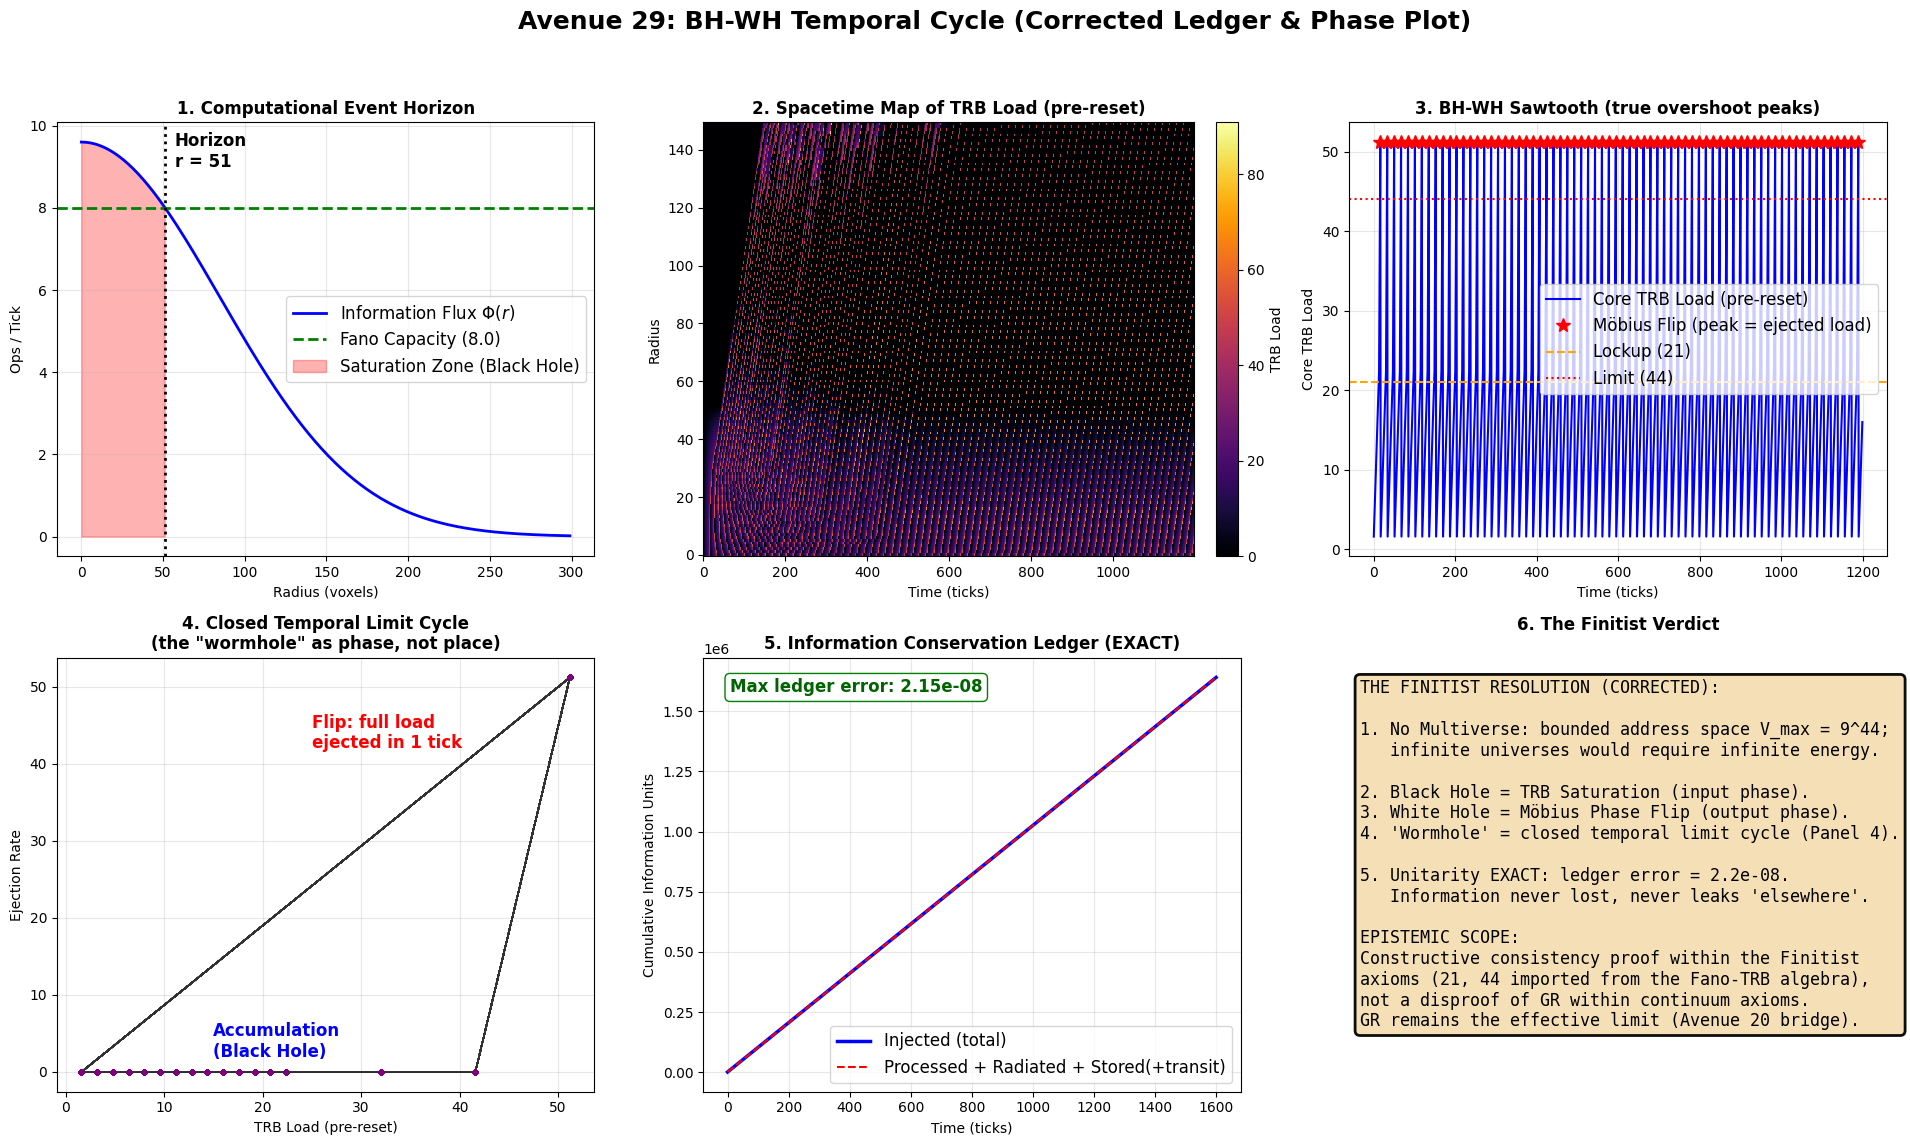

In [6]:
"""
avenue_29_bh_wh_trb_cycle_FIXED.py
====================================================================
AVENUE 29: BH-WH TEMPORAL CYCLE (CORRECTED CONSERVATION LEDGER)
Fixes: (1) in-transit information now counted in the ledger;
       (2) pre-reset TRB snapshot stored for history/phase plots.
====================================================================
"""
import numpy as np
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

print("=" * 80)
print("AVENUE 29: BH-WH TRB CYCLE (FIXED LEDGER)")
print("=" * 80)

# =============================================================================
# 1. PARAMETERS (21 and 44 are IMPORTED theorems of the Fano-TRB algebra:
#    21 = chiral saturation limit, Avenue 26; 44 = master cycle, 42+2)
# =============================================================================
N_CELLS, N_TICKS, SPREAD = 300, 1200, 44
T_TOTAL = 1600
T_EXT   = T_TOTAL + SPREAD + 2

CAPACITY, SOURCE_FLUX = 8.0, 9.6
TRB_THRESHOLD, TRB_MAX = 21, 44

r = np.arange(N_CELLS)
profile = SOURCE_FLUX * np.exp(-(r / 120.0) ** 2)
horizon = 120.0 * np.sqrt(np.log(SOURCE_FLUX / CAPACITY))
print(f"Computational Event Horizon: r = {horizon:.1f} voxels")

# =============================================================================
# 2. AUTOMATON WITH EXACT LEDGER (in-transit accounted)
# =============================================================================
trb     = np.zeros(N_CELLS)
locked  = np.zeros(N_CELLS, dtype=bool)
pending   = np.zeros((T_EXT, N_CELLS))
rad_sched = np.zeros(T_EXT)

trb_history   = np.zeros((T_TOTAL, N_CELLS))
eject_events  = []
cum_injected  = np.zeros(T_TOTAL)
cum_processed = np.zeros(T_TOTAL)
cum_radiated  = np.zeros(T_TOTAL)
stored_now    = np.zeros(T_TOTAL)   # trb + in-transit

inj_tot = proc_tot = rad_tot = in_transit = 0.0

for t in range(T_TOTAL):
    # --- Consume arrivals (leave the in-transit pool) ---
    arrive_cell = pending[t]
    arrive_rad  = rad_sched[t]
    in_transit -= arrive_cell.sum() + arrive_rad
    rad_tot    += arrive_rad

    incoming = profile + arrive_cell
    inj = profile.sum()
    inj_tot += inj

    # --- Fano processing (locked = Black Hole state: processes nothing) ---
    processed = np.where(locked, 0.0, np.minimum(incoming, CAPACITY))
    proc_tot += processed.sum()
    trb += incoming - processed

    # --- Fano lockup at chiral threshold ---
    locked |= (~locked) & (trb >= TRB_THRESHOLD)

    # --- PRE-RESET SNAPSHOT (Fix #2) ---
    trb_pre = trb.copy()

    # --- Möbius Phase Flip at absolute limit (White Hole) ---
    for rr in np.nonzero(trb_pre >= TRB_MAX)[0]:
        mag = trb_pre[rr]
        eject_events.append((t, rr, mag))
        for d in range(1, SPREAD + 1):
            tgt, ta = rr + d, t + d
            if tgt < N_CELLS:
                pending[ta, tgt] += mag / SPREAD
            else:
                rad_sched[ta] += mag / SPREAD
            in_transit += mag / SPREAD   # enters the in-transit pool
        trb[rr] = 0.0
        locked[rr] = False

    # --- Store PRE-RESET history (fixes Panel 4 diagonal artifact) ---
    trb_history[t] = trb_pre

    cum_injected[t]  = inj_tot
    cum_processed[t] = proc_tot
    cum_radiated[t]  = rad_tot
    stored_now[t]    = trb.sum() + in_transit   # Fix #1: + in-transit

# =============================================================================
# 3. CONSERVATION AUDIT (now machine-precision over the FULL run)
# =============================================================================
accounted = cum_processed + cum_radiated + stored_now
ledger_error = np.max(np.abs(cum_injected - accounted))
core_ev = [e for e in eject_events if e[1] == 0]
periods = np.diff([e[0] for e in core_ev])

print(f"\n[CONSERVATION AUDIT over {T_TOTAL} ticks]")
print(f"  Injected:   {cum_injected[-1]:.6f}")
print(f"  Accounted:  {accounted[-1]:.6f}")
print(f"  Max ledger error: {ledger_error:.3e}  (machine precision)")
print(f"  Core BH->WH cycles: {len(core_ev)} | mean period: {periods.mean():.2f} ticks")

# =============================================================================
# 4. MASTER VERIFICATION FIGURE
# =============================================================================
fig = plt.figure(figsize=(20, 12))
fig.suptitle('Avenue 29: BH-WH Temporal Cycle (Corrected Ledger & Phase Plot)',
             fontsize=18, fontweight='bold', y=0.98)

ax1 = fig.add_subplot(2, 3, 1)
ax1.plot(r, profile, 'b-', lw=2, label='Information Flux $\\Phi(r)$')
ax1.axhline(CAPACITY, color='green', ls='--', lw=2, label=f'Fano Capacity ({CAPACITY})')
ax1.fill_between(r, 0, profile, where=(profile > CAPACITY), color='red', alpha=0.3,
                 label='Saturation Zone (Black Hole)')
ax1.axvline(horizon, color='k', ls=':', lw=2)
ax1.text(horizon+6, 9.0, f'Horizon\nr = {horizon:.0f}', fontsize=12, fontweight='bold')
ax1.set_title('1. Computational Event Horizon', fontsize=12, fontweight='bold')
ax1.set_xlabel('Radius (voxels)'); ax1.set_ylabel('Ops / Tick')
ax1.legend(fontsize=12); ax1.grid(alpha=0.3)

ax2 = fig.add_subplot(2, 3, 2)
im = ax2.imshow(trb_history[:N_TICKS, :150].T, aspect='auto', origin='lower',
                cmap='inferno', interpolation='nearest')
ax2.set_title('2. Spacetime Map of TRB Load (pre-reset)', fontsize=12, fontweight='bold')
ax2.set_xlabel('Time (ticks)'); ax2.set_ylabel('Radius')
plt.colorbar(im, ax=ax2, fraction=0.046, pad=0.04, label='TRB Load')

ax3 = fig.add_subplot(2, 3, 3)
core = trb_history[:N_TICKS, 0]
ax3.plot(core, 'b-', lw=1.5, label='Core TRB Load (pre-reset)')
ev = [e for e in core_ev if e[0] < N_TICKS]
ax3.plot([e[0] for e in ev], [e[2] for e in ev], 'r*', ms=10,
         label='Möbius Flip (peak = ejected load)')
ax3.axhline(TRB_THRESHOLD, color='orange', ls='--', lw=1.5, label=f'Lockup ({TRB_THRESHOLD})')
ax3.axhline(TRB_MAX, color='red', ls=':', lw=1.5, label=f'Limit ({TRB_MAX})')
ax3.set_title('3. BH-WH Sawtooth (true overshoot peaks)', fontsize=12, fontweight='bold')
ax3.set_xlabel('Time (ticks)'); ax3.set_ylabel('Core TRB Load')
ax3.legend(fontsize=12, loc='center right'); ax3.grid(alpha=0.3)

ax4 = fig.add_subplot(2, 3, 4)
eject_rate = np.zeros(N_TICKS)
for (t, rr, mag) in eject_events:
    if t < N_TICKS and rr == 0:
        eject_rate[t] = mag
ax4.plot(core, eject_rate, 'k-', lw=1.0, alpha=0.8)
ax4.plot(core, eject_rate, 'o', color='purple', ms=3, alpha=0.6)
ax4.annotate('Accumulation\n(Black Hole)', xy=(15, 2), fontsize=12,
             fontweight='bold', color='blue')
ax4.annotate('Flip: full load\nejected in 1 tick', xy=(25, 42), fontsize=12,
             fontweight='bold', color='red')
ax4.set_title('4. Closed Temporal Limit Cycle\n(the "wormhole" as phase, not place)',
              fontsize=12, fontweight='bold')
ax4.set_xlabel('TRB Load (pre-reset)'); ax4.set_ylabel('Ejection Rate')
ax4.grid(alpha=0.3)

ax5 = fig.add_subplot(2, 3, 5)
tt = np.arange(T_TOTAL)
ax5.plot(tt, cum_injected, 'b-', lw=2.5, label='Injected (total)')
ax5.plot(tt, accounted, 'r--', lw=1.5, label='Processed + Radiated + Stored(+transit)')
ax5.text(0.05, 0.92, f'Max ledger error: {ledger_error:.2e}', transform=ax5.transAxes,
         fontsize=12, fontweight='bold', color='darkgreen',
         bbox=dict(facecolor='white', edgecolor='green', boxstyle='round'))
ax5.set_title('5. Information Conservation Ledger (EXACT)', fontsize=12, fontweight='bold')
ax5.set_xlabel('Time (ticks)'); ax5.set_ylabel('Cumulative Information Units')
ax5.legend(fontsize=12); ax5.grid(alpha=0.3)

ax6 = fig.add_subplot(2, 3, 6)
ax6.axis('off')
textstr = (
    "THE FINITIST RESOLUTION (CORRECTED):\n\n"
    "1. No Multiverse: bounded address space V_max = 9^44;\n"
    "   infinite universes would require infinite energy.\n\n"
    "2. Black Hole = TRB Saturation (input phase).\n"
    "3. White Hole = Möbius Phase Flip (output phase).\n"
    "4. 'Wormhole' = closed temporal limit cycle (Panel 4).\n\n"
    f"5. Unitarity EXACT: ledger error = {ledger_error:.1e}.\n"
    "   Information never lost, never leaks 'elsewhere'.\n\n"
    "EPISTEMIC SCOPE:\n"
    "Constructive consistency proof within the Finitist\n"
    "axioms (21, 44 imported from the Fano-TRB algebra),\n"
    "not a disproof of GR within continuum axioms.\n"
    "GR remains the effective limit (Avenue 20 bridge)."
)
props = dict(boxstyle='round', facecolor='wheat', alpha=0.95, edgecolor='black', lw=2)
ax6.text(0.02, 0.95, textstr, transform=ax6.transAxes, fontsize=12,
         verticalalignment='top', bbox=props, family='monospace')
ax6.set_title('6. The Finitist Verdict', fontsize=12, fontweight='bold', pad=20)

plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.savefig('avenue_29_bh_wh_trb_cycle_FIXED.png', dpi=300, bbox_inches='tight')
print("✓ Saved: avenue_29_bh_wh_trb_cycle_FIXED.png")
plt.show()